# Build sum-of-products KEO for water ($\mathrm{H_2O}$) in Jacobi coordinates

In [49]:
import matplotlib.pyplot as plt
import numpy as np
import seaborn as sns
from scipy import constants

from keosop.sing.gmat import Gmat
from keosop.sing.revad import dot, norm

sns.set_theme(style="ticks", context="paper", font_scale=1.5)
plt.rcParams["figure.dpi"] = 300
plt.rcParams.update({"text.usetex": True, "font.family": "serif", "font.size": 14})

# converts G-matrix to cm^-1 units
G_to_invcm = (
    constants.value("Planck constant")
    * constants.value("Avogadro constant")
    * 1e16
    / (4.0 * np.pi**2 * constants.value("speed of light in vacuum"))
    * 1e5
)

Define the internal-to-Cartesian and Cartesian-to-internal coordinate transformations for $\mathrm{H_2O}$.

The internal coordinates are defined as:

1. $r$ — O-H1 bond length, $\mathbf{r}=\mathbf{r}_{O}-\mathbf{r}_{H_1}$
2. $R$ — distance between O-H1 centre of mass and H2, $\mathbf{R}=\mathbf{r}_{H_2}-(m_{H_1}\mathbf{r}_{H_1}+m_{O}\mathbf{r}_{O})/(m_{H_1}+m_{O})$
3. $\theta$ — angle between the Jacobi vectors, $\theta=\arccos{(\mathbf{r}\cdot\mathbf{R})/(rR)}$

The atom ordering in Cartesian coordinates is: $\mathrm{H_1},\ \mathrm{O},\ \mathrm{H_2}$

In [50]:
masses = np.array([1.0078250, 15.99491463, 1.00782505])  # masses of H, O, H

ncoo = 3


def internal_to_cartesian(q):
    R, r, theta = q

    mA, mB, mC = masses
    mAB = mA + mB

    A = np.array([0.0, 0.0, -mB / mAB * r], dtype=object)
    B = np.array([0.0, 0.0, mA / mAB * r], dtype=object)
    C = np.array([R * np.sin(theta), 0.0, R * np.cos(theta)], dtype=object)

    return np.array([A, B, C], dtype=object)


def cartesian_to_internal(xyz):
    A, B, C = xyz

    mA, mB, mC = masses
    mAB = mA + mB

    rvec = B - A
    r = norm(rvec)

    comAB = (mA * A + mB * B) / mAB
    Rvec = C - comAB
    R = norm(Rvec)

    theta = np.arccos(dot(rvec, Rvec) / (r * R))

    return np.array([R, r, theta], dtype=object)

Define one-dimensional grids for the internal coordinate representation and construct the G-matrix in sum-of-products form

In [87]:
grids = [
    np.linspace(1.0, 1.0, 1),  # r1
    np.linspace(1.0, 1.0, 1),  # r2
    np.linspace(0.1 * np.pi / 180, 179.9 * np.pi / 180, 100),  # theta
]

gmat = Gmat(
    grids,
    masses,
    internal_to_cartesian,
    cartesian_to_internal,
    trace_singularities=True,
    singularity_coo=(2,),
    singularity_kinds=("sin",),
)

gvib_sop, grovib_sop, grot_sop = gmat.run(return_rot=True)
pseudo_sop = gmat.build_pseudopotential_fdf(fd_step=0.001)

print("Number of terms in Gvib_{i,j}\n i  j no.terms  sing. summary")
for i in range(ncoo):
    for j in range(i, ncoo):
        print(
            f"{i:2d} {j:2d} {gvib_sop[i, j].nterms:6d}    {gvib_sop[i,j].singularity_summary()}"
        )

print("\nNumber of terms in Grovib_{i,j}\n i  j no.terms  sing. summary")
for i in range(3):
    for j in range(ncoo):
        print(
            f"{i:2d} {j:2d} {grovib_sop[i, j].nterms:6d}    {grovib_sop[i,j].singularity_summary()}"
        )

print("\nNumber of terms in Grot_{i,j}\n i  j no.terms  sing. summary")
for i in range(3):
    for j in range(i, 3):
        print(
            f"{i:2d} {j:2d} {grot_sop[i, j].nterms:6d}    {grot_sop[i,j].singularity_summary()}"
        )

print("\nNumber of terms in pseudopotential\n no.terms  sing. summary")
print(f"{pseudo_sop.nterms:6d}    {pseudo_sop.singularity_summary()}")

Number of terms in Gvib_{i,j}
 i  j no.terms  sing. summary
 0  0      1    {(): 1}
 0  1      1    {(): 1}
 0  2      1    {(): 1}
 1  1      1    {(): 1}
 1  2      1    {(): 1}
 2  2      1    {(): 1}

Number of terms in Grovib_{i,j}
 i  j no.terms  sing. summary
 0  0      1    {(): 1}
 0  1      1    {(): 1}
 0  2      1    {(): 1}
 1  0      1    {(): 1}
 1  1      1    {(): 1}
 1  2      1    {(): 1}
 2  0      1    {(): 1}
 2  1      1    {(): 1}
 2  2      1    {(): 1}

Number of terms in Grot_{i,j}
 i  j no.terms  sing. summary
 0  0      1    {(): 1}
 0  1      1    {(): 1}
 0  2      1    {((2, 'sin', -2.0),): 1}
 1  1      1    {(): 1}
 1  2      1    {(): 1}
 2  2      1    {((2, 'sin', -2.0),): 1}

Number of terms in pseudopotential
 no.terms  sing. summary
     2    {((2, 'sin', -2.0),): 1, (): 1}


One can see from the previous cell output that pseudopotential contains one terms multiplied by $\sin^{-2}(q_2)$ and one regular (non-singular term), i.e., $U=U_0+U_1/\sin^2\theta$.

Since the separation into $U_0$ and $U_1$ is noncanonical, we compare with analytic expression the quantity $\tilde{U}=\sin^2\theta U_0+U_1$, which is calculated below on grid

In [88]:
# evaluate one SOP term
def eval_sop_term(sop, iterm, inds, grids):

    theta = grids[-1][inds[-1]]

    # regular numerical SOP part
    value = 1.0
    for k in range(sop.ncoo):
        value *= sop.terms[iterm][k][inds[k]]

    # if term contains no analytical singular part -> multiply it by sin^2(theta)
    if not sop.singularities[iterm]:
        value *= np.sin(theta) ** 2

    # if term contains sin^2(q[2]) analytical singular part -> skip it
    for k, kind, power in sop.singularities[iterm]:
        q = grids[k][inds[k]]
        if kind == "sin" and k == 2:
            continue
        else:
            raise ValueError(f"Unknown singularity kind: {kind}, coo. {k}")

    return value


# evaluate a complete SumProd object at one direct-product grid point
def eval_sop(sop, inds, grids):
    return sum(eval_sop_term(sop, iterm, inds, grids) for iterm in range(sop.nterms))


# number of multidimensional grid points
grid = np.stack(np.meshgrid(*grids, indexing="ij"), axis=-1)
grid = grid.reshape(-1, len(grids))
npoints = grid.shape[0]

grot_zz_sop_eval = np.zeros((npoints,), dtype=np.float64)
pseudo_sop_eval = np.zeros((npoints,), dtype=np.float64)

# map each multidimensional grid point to its 1D grid indices
grid_indices = np.indices([len(elem) for elem in grids]).reshape(len(grids), -1).T

for ipoint, inds in enumerate(grid_indices):
    grot_zz_sop_eval[ipoint] = eval_sop(grot_sop[2, 2], inds, grids) * G_to_invcm

for ipoint, inds in enumerate(grid_indices):
    pseudo_sop_eval[ipoint] = eval_sop(pseudo_sop, inds, grids) * G_to_invcm

Compute pseudopotential $\tilde{U}=U\sin^2\theta$ using analytic expression

In [89]:
def pseudo_analytic(q):
    R, r, theta = q
    mH, mC, mN = masses

    A = (
        R**2 * mH * mN**2
        + mC**2 * (R**2 * mH + r**2 * mN)
        + mC * mN * ((r**2 + 2 * R**2) * mH + r**2 * mN)
    ) / (16 * r**2 * R**2 * mC * mH * mN * (mC + mN))

    U_regular_times_sin2theta = -2.0 * A * np.sin(theta) ** 2
    U_singular_times_sin2theta = -2.0 * A

    return (U_regular_times_sin2theta + U_singular_times_sin2theta) * G_to_invcm


def gzz_analytic(q):
    R, r, theta = q
    mH, mC, mN = masses
    G = (
        1 / (R**2 * mH)
        + 1 / (r**2 * (mC + mN))
        + 1 / (R**2 * (mC + mN))
        + np.cos(2 * theta) / (r**2 * (mC + mN))
        + np.cos(theta) ** 2 * mC / (r**2 * mN * (mC + mN))
        + np.cos(theta) ** 2 * mN / (r**2 * mC * (mC + mN))
    )
    return G*G_to_invcm


pseudo_analytic_eval = []
gzz_analytic_eval = []
for point in grid:
    pseudo_analytic_eval.append(pseudo_analytic(point))
    gzz_analytic_eval.append(gzz_analytic(point))
pseudo_analytic_eval = np.array(pseudo_analytic_eval)
gzz_analytic_eval = np.array(gzz_analytic_eval)

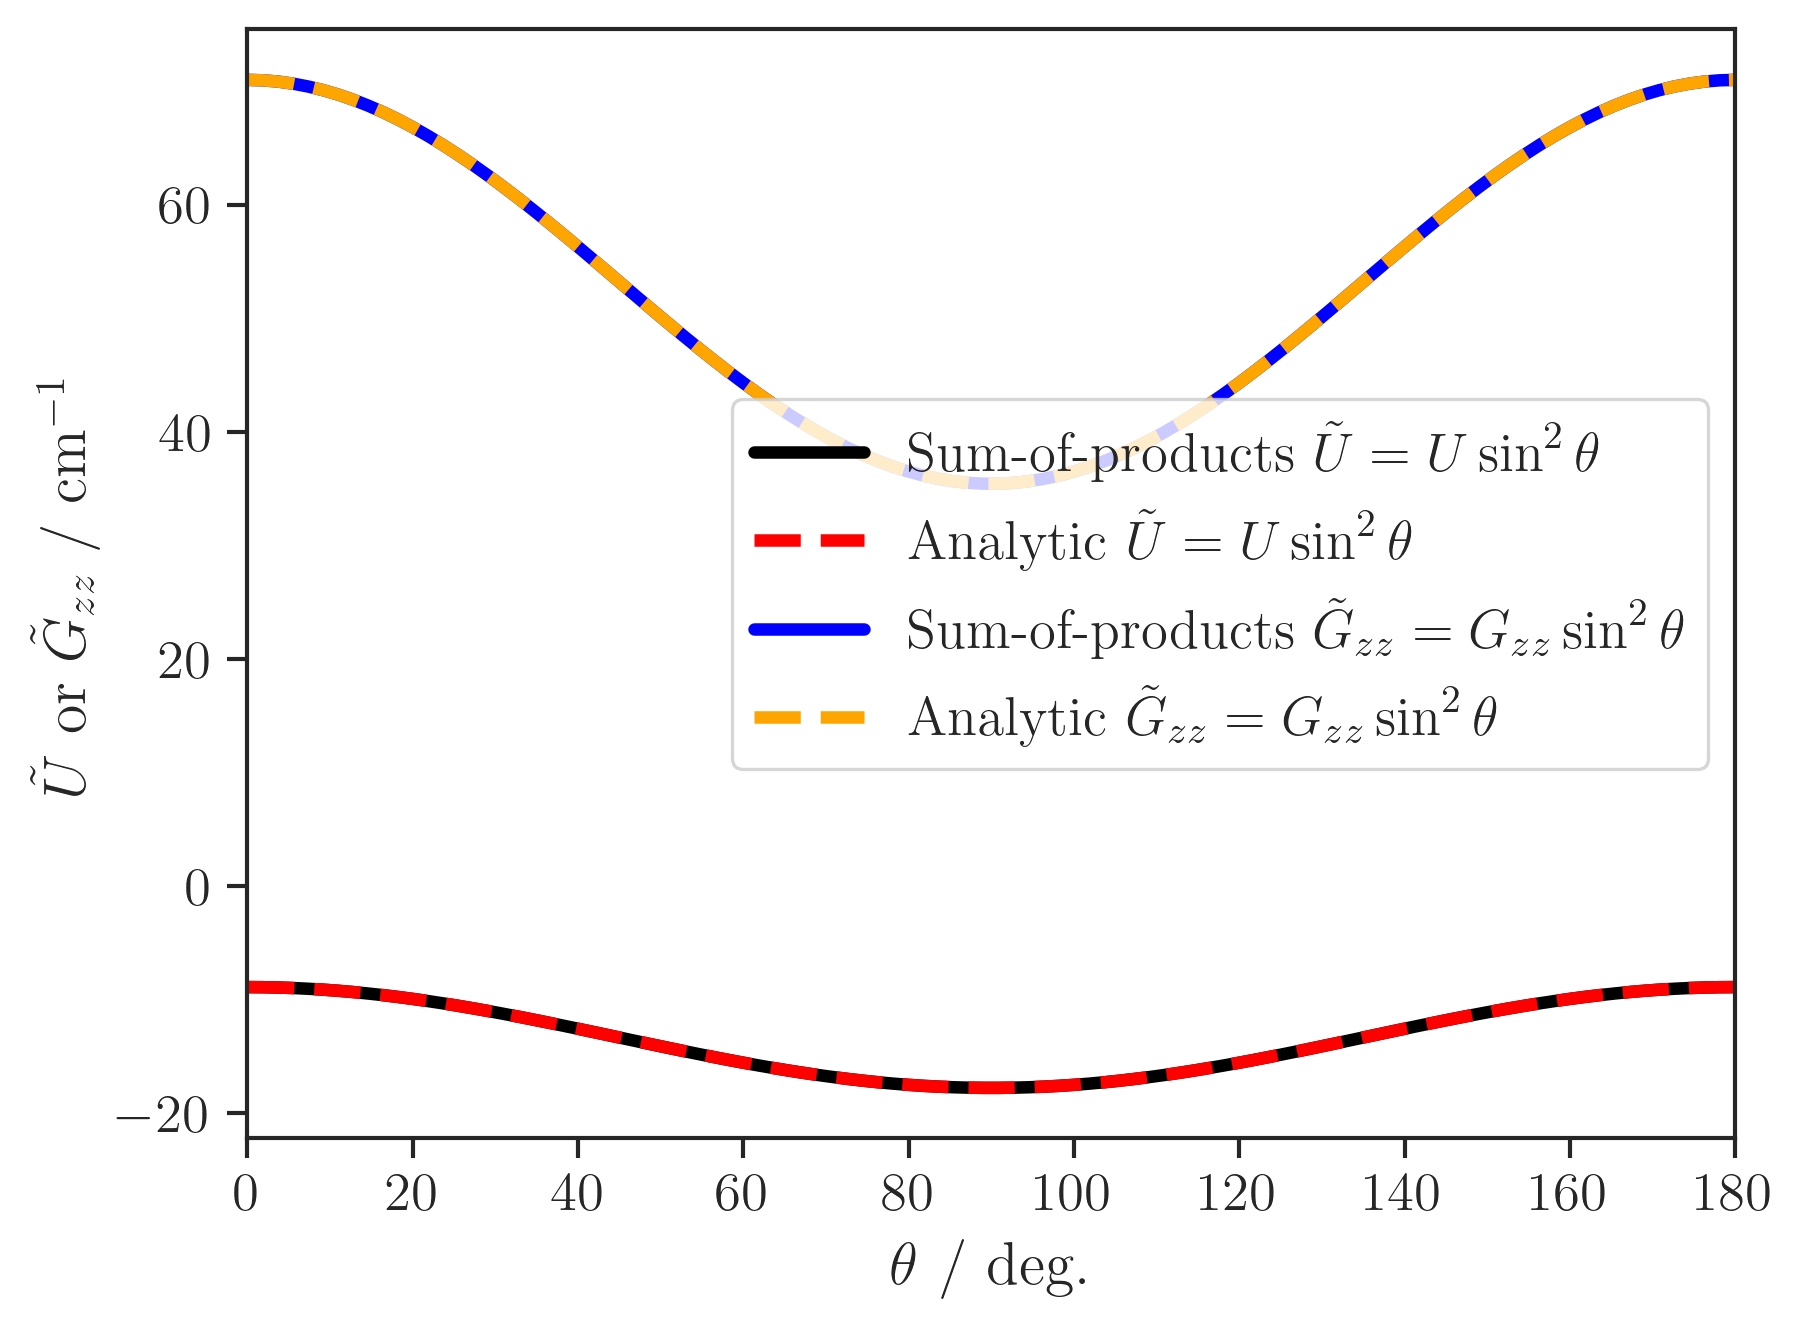

In [111]:
theta = grid[:, -1] * 180 / np.pi

plt.plot(
    theta,
    pseudo_sop_eval,
    label=r"Sum-of-products $\tilde{U}=U\sin^2\theta$",
    linewidth=3,
    color="black",
)
plt.plot(
    theta,
    pseudo_analytic_eval,
    linestyle="--",
    label=r"Analytic $\tilde{U}=U\sin^2\theta$",
    linewidth=3,
    color="red",
)

plt.plot(
    theta,
    grot_zz_sop_eval,
    label=r"Sum-of-products $\tilde{G}_{zz}=G_{zz}\sin^2\theta$",
    linewidth=3,
    color="blue",
)
plt.plot(
    theta,
    gzz_analytic_eval,
    linestyle="--",
    label=r"Analytic $\tilde{G}_{zz}=G_{zz}\sin^2\theta$",
    linewidth=3,
    color="orange",
)

plt.xlabel(r"$\theta$ / deg.")
plt.ylabel(r"$\tilde{U}$ or $\tilde{G}_{zz}$ / $\mathrm{cm^{-1}}$")
plt.xlim([0, 180])
plt.legend()

plt.savefig("h2o_jacobi_sing.pdf", bbox_inches="tight", dpi=300)
plt.show()
